# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 2

### 2025-2026

# Importing necessary libraries

In [219]:
import torch
import torch.nn as nn
from torch.autograd import grad
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_moons

# Adaline

1. Build the ADALINE model using the `nn.Module` class. The model performs a linear transformation $\hat{y} = Xw^T + b$, with weights and bias initialised to zero.

In [220]:
class Adaline(torch.nn.Module):
    def __init__(self, num_features):
        super(Adaline, self).__init__()
        self.linear =  nn.Linear(num_features, 1) 
        with torch.no_grad():
            self.linear.weight.zero_() 
            self.linear.bias.zero_() 
    def forward(self, x):
        activations = self.linear(x)
        return activations.view(-1)

2. Using 'iris.txt', create a binary dataset in 2-D : the last 100 instances of iris described only by the 2nd and 3rd features.

    Split the dataset into training and test sets (70%, 30%).

    Normalize the dataset. **Why must the mean and standard deviation be computed on the training set only?**

In [221]:
df = pd.read_csv('iris.txt', index_col=None, header=None)
df.columns = ['x1', 'x2', 'x3', 'x4', 'y']
df = df.iloc[50:150]                         # last 100 instances (2 last classes)
df['y'] = df['y'].apply(lambda x: 0 if x == 'Iris-versicolor' else 1)

# Assign features and target
X = torch.tensor(df[['x2', 'x3']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train_iris, X_test_iris = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train_iris, y_test_iris = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance) : 
mu, sigma = X_train_iris.mean(axis=0), X_train_iris.std(axis=0)
X_train_iris = (X_train_iris - mu)/sigma
X_test_iris = (X_test_iris - mu)/sigma

mu_train, sigma_train = X_train_iris.mean(), X_train_iris.std()

print(f"Moyenne : {mu_train} & Sigma : {sigma_train}")


Moyenne : 2.2138868516208277e-08 & Sigma : 0.9963963627815247


Les statistiques de normalisation se calculent sur le train pour éviter une fuite d’information du test vers l’entraînement. Le test doit rester un jeu jamais vu.

In [222]:
model = Adaline(num_features=X_train_iris.size(1))
model

Adaline(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

3. Train the model : we will use `MSELoss` (mean squared error) as loss function. The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

    The function `train` must **return the list of the loss values at each epoch**. Plot this cost curve.

In [223]:
def train(model, x, y, num_epochs, learning_rate, seed):
    cost = []
    torch.manual_seed(seed)
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) 
    loss = nn.MSELoss() 
    for e in range(num_epochs):
        y_pred = model(x)
        #y_pred = model.forward(x)
        
        loss_value = loss(y_pred,y)
        optimizer.zero_grad()

        loss_value.backward()

        optimizer.step()#IMPORTANT Sans ça on a une droite et non une courbe
        #Cette instruction permet de mettre à jour les paramètres du modèle après le calcul des gradients.

        cost.append(loss_value.item())
        #CONSIGNE : 
        # forward pass, loss, gradient reset, backward pass, update
        # store the loss of the epoch in cost
        pass
    return cost

[0.5285714268684387, 0.5104926228523254, 0.4932100474834442, 0.4766862690448761, 0.46088555455207825, 0.4457741677761078, 0.43131980299949646, 0.41749200224876404, 0.4042615592479706, 0.39160093665122986, 0.3794836699962616, 0.3678847849369049, 0.3567804992198944, 0.34614813327789307, 0.3359660804271698, 0.3262139856815338, 0.31687211990356445, 0.30792203545570374, 0.2993459403514862, 0.2911270558834076, 0.28324928879737854, 0.2756973206996918, 0.26845669746398926, 0.26151350140571594, 0.2548545002937317, 0.2484670877456665, 0.2423393577337265, 0.23645980656147003, 0.2308175265789032, 0.22540219128131866, 0.22020384669303894, 0.21521306037902832, 0.21042083203792572, 0.2058185338973999, 0.20139800012111664, 0.19715142250061035, 0.19307129085063934, 0.18915054202079773, 0.18538236618041992, 0.1817602515220642, 0.17827804386615753, 0.17492981255054474, 0.17170993983745575, 0.1686129868030548, 0.16563384234905243, 0.16276754438877106, 0.1600094586610794, 0.15735508501529694, 0.15480008721

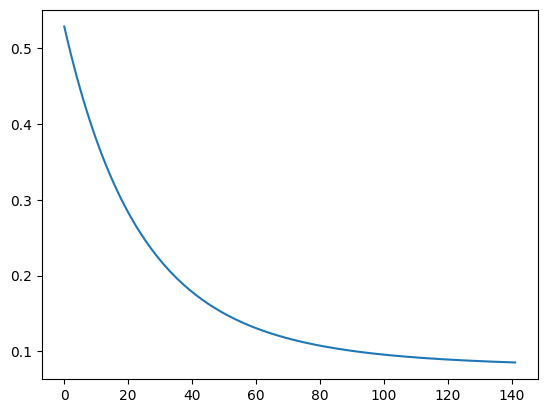

In [224]:
cost = train(model, X_train_iris, y_train_iris.float(), num_epochs=142, learning_rate=0.01, seed=123)
print(cost)
plt.plot(cost)
plt.show()

4. Compute the model accuracy

In [225]:
def custom_where(cond, x_1, x_2):
    return (cond * x_1) + (torch.logical_not(cond) * x_2)

train_pred = model.forward(X_train_iris)
train_acc = torch.mean((custom_where(train_pred > 0.5, 1, 0).int() == y_train_iris).float())
test_pred = model.forward(X_test_iris)
test_acc = torch.mean((custom_where(test_pred > 0.5, 1, 0).int() == y_test_iris).float())
print('Training Accuracy: %.2f' % (train_acc*100))
print('Test Accuracy: %.2f' % (test_acc*100))
print('Weights', model.linear.weight)
print('Bias', model.linear.bias)

Training Accuracy: 92.86
Test Accuracy: 90.00
Weights Parameter containing:
tensor([[-0.0336,  0.3843]], requires_grad=True)
Bias Parameter containing:
tensor([0.4986], requires_grad=True)


5. a. Plot the training points (one color per class) and the decision boundary of the Adaline. Give the equation of this boundary as a function of $w_1$, $w_2$ and $b$ (be careful: the threshold is 0.5, not 0).

   b. Train a new Adaline for each learning rate in {0.001, 0.01, 0.1, 0.5} and plot the 4 cost curves on the same figure. What happens for the largest value? Explain.

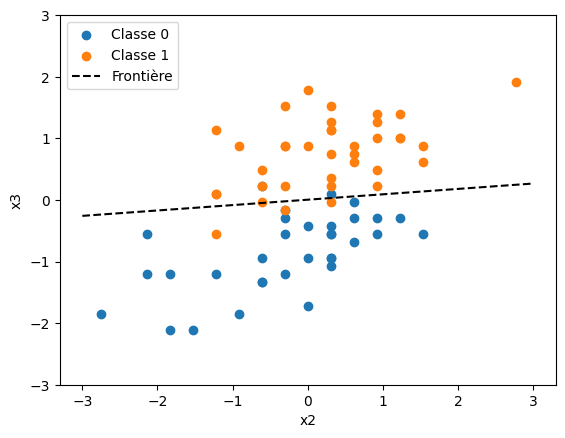

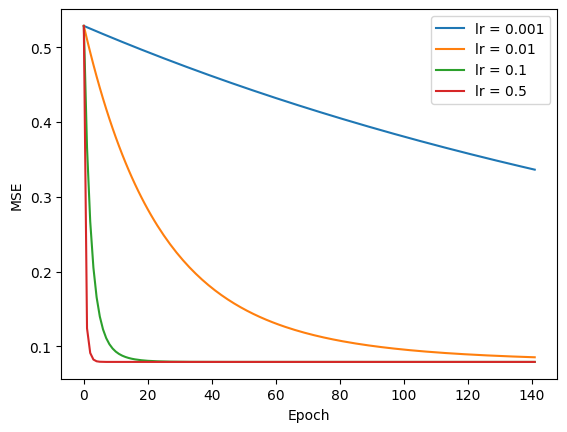

In [226]:
# on recup les paramètres du modèle entraîné
w1 = model.linear.weight[0][0].item()
w2 = model.linear.weight[0][1].item()
b = model.linear.bias.item()

# formule : w1*x1 + w2*x2 + b = 0.5  (seuil à 0.5 et pas 0)
# donc x2 = (0.5 - b - w1*x1) / w2
x1 = np.linspace(-3, 3, 100)
x2 = (0.5 - b - w1 * x1) / w2

plt.figure()
plt.scatter(X_train_iris[y_train_iris == 0, 0], X_train_iris[y_train_iris == 0, 1], label="Classe 0")
plt.scatter(X_train_iris[y_train_iris == 1, 0], X_train_iris[y_train_iris == 1, 1], label="Classe 1")
plt.plot(x1, x2, "k--", label="Frontière")
plt.ylim(-3, 3)  # sinon la droite écrase le graphique
plt.xlabel("x2")
plt.ylabel("x3")
plt.legend()
plt.show()


# 5b :
plt.figure()
for lr in [0.001, 0.01, 0.1, 0.5]:
    m = Adaline(num_features=X_train_iris.size(1))
    c = train(m, X_train_iris, y_train_iris.float(), num_epochs=142, learning_rate=lr, seed=123) # valeurs des param de Q3
    plt.plot(c, label=f"lr = {lr}")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

- Pour lr = 0,5, la MSE converge en quelques époques, beaucoup plus vite que pour les autres valeurs.
- Sur des données normalisées, la descente de gradient sur la MSE est stable tant que lr < 1/(1+r), seuil supérieur à 0,5 ; ce learning rate est donc admissible ici et optimal en vitesse
- Toutes les valeurs convergent vers le même minimum (MSE ≈ 0,08) : le learning rate n’influe que sur la vitesse
- lr = 0,001 est trop petit : à 142 époques la MSE vaut encore 0,33
- Un learning rate plus grand (≈ 1 ou plus) aurait fini par faire diverger la loss.

# Perceptron

6. Build a Perceptron model **from scratch** (without autograd and without optimizer):
    - `forward` returns the predictions in {0, 1} (step function),
    - `backward` returns the errors $y - \hat{y}$,
    - `train` applies the perceptron learning rule example by example, and must **return the number of misclassified examples at each epoch**.

In [227]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

class Perceptron():
    def __init__(self, num_features):
        self.num_features = num_features
        self.weights = torch.zeros(num_features, 1, dtype=torch.float32, device=device)
        self.bias = torch.zeros(1, dtype=torch.float32, device=device)
        self.ones = torch.ones(1, device=device)
        self.zeros = torch.zeros(1, device=device)

    def forward(self, x):
        y  = torch.mm(x, self.weights) + self.bias
        prediction = torch.where(y > 0, self.ones, self.zeros)
        return prediction

    def backward(self, x, y):
        y_ = self.forward(x)
        errors = y  - y_
        return errors

    def train(self, x, y, epochs):
        n_errors = []
        for e in range(epochs):
            for i in range(y.shape[0]):
                errors = y[i] - self.forward(x[i].view(1, -1)) # transf vecteur en 1 ligne
                self.weights += errors * x[i].view(-1, 1) # tenseur en col
                self.bias += errors.view(-1) # transf en 1D
            prediction = self.forward(x)
            cpt = (prediction.view(-1) != y).sum().item()
            n_errors.append(cpt)
        return n_errors

    def evaluate(self, x, y):
        predictions = self.forward(x).reshape(-1)
        accuracy = torch.sum(predictions == y).float() / y.shape[0]
        return accuracy

7. Load the 'perceptron_toydata' dataset

    Split the dataset into train and test sets

    Normalize the data

In [228]:
df = pd.read_csv('perceptron_toydata.txt', index_col=None, header=None, delimiter='\t')
df.columns = ['x1', 'x2', 'y']
X = torch.tensor(df[['x1', 'x2']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)
print('Class label counts:', torch.bincount(y))
print('X.shape:', X.shape)
print('y.shape:', y.shape)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

Class label counts: tensor([50, 50])
X.shape: torch.Size([100, 2])
y.shape: torch.Size([100])


8. Train the perceptron and plot the number of errors per epoch.

Model parameters:
  Weights: tensor([[2.4396],
        [1.5818]])
  Bias: tensor([-1.])


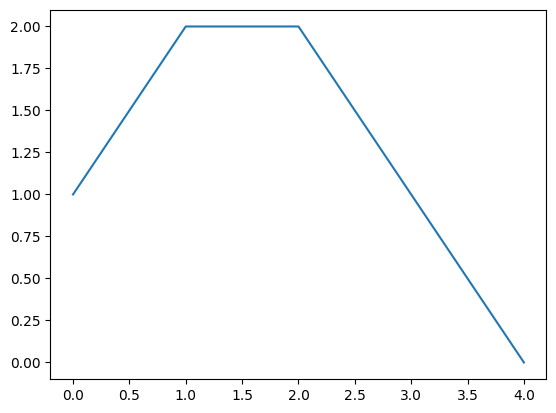

In [229]:
model_perceptron = Perceptron(num_features=2)

X_train_tensor = X_train.clone().detach().to(device)
y_train_tensor = y_train.clone().detach().float().to(device)

n_errors = model_perceptron.train(X_train_tensor, y_train_tensor, epochs=5)

print('Model parameters:')
print('  Weights: %s' % model_perceptron.weights)
print('  Bias: %s' % model_perceptron.bias)
# TODO : plot n_errors
plt.plot(n_errors)
plt.show()

9. Evaluate the model (accuracy)

In [230]:
X_test_tensor = X_test.clone().detach().to(device)
y_test_tensor = y_test.clone().detach().float().to(device)

test_acc = model_perceptron.evaluate(X_test_tensor, y_test_tensor)
print('Test set accuracy: %.2f%%' % (test_acc*100))

Test set accuracy: 93.33%


10. a. Plot the test points and the decision boundary of the perceptron.

    b. Under which condition on the data is the perceptron learning rule guaranteed to converge? Train your perceptron for 20 epochs on the **iris dataset of the Adaline part** and plot the number of errors per epoch. What do you observe? Compare with the Adaline and explain.

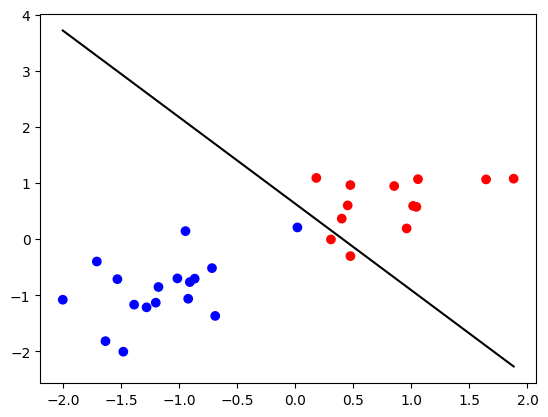

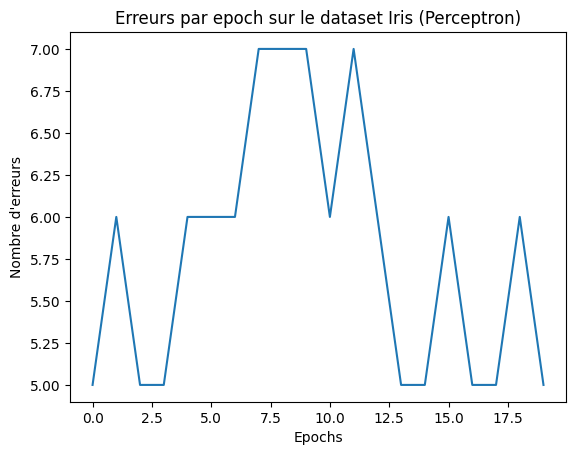

In [231]:
#a
#La fonction cpu() sert a ramneer les données du GPU vers le CPU

w = model_perceptron.weights.cpu().numpy().flatten()
b = model_perceptron.bias.cpu().numpy()[0]

x_line = np.array([X_test[:, 0].min(), X_test[:, 0].max()])
y_line = (-b - w[0] * x_line) / w[1]

plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr')
plt.plot(x_line, y_line, color='black')
plt.show()

#b
perceptron_iris = Perceptron(num_features=2)

X_iris_train = X_train_iris.to(device)
y_iris_train = y_train_iris.float().to(device)

n_errors_iris = perceptron_iris.train(X_iris_train, y_iris_train, epochs=20)

plt.plot(n_errors_iris)
plt.xlabel("Epochs")
plt.ylabel("Nombre d'erreurs")
plt.title("Erreurs par epoch sur le dataset Iris (Perceptron)")
plt.show()

- Les erreurs oscillent et ne descendent jamais à zéro.
- Le dataset Iris n'est pas linéairement séparable, et le Perceptron ne peut pas converger sans séparation parfaite.
- L'Adaline trouve un compromis stable grâce à sa fonction d'erreur continue, tandis que le Perceptron tourne en boucle et échoue face à des données qui se chevauchent.

# Multi Layer Perceptron

Unlike the single-layer perceptron, the Multi Layer Perceptron models have hidden layers
between the input and the output layers. After every hidden layer, an activation function
is applied to introduce non-linearity.

11. Build a simple Multi Layer Perceptron model with one hidden layer.
After the hidden layer, we will use ReLU as activation before the information is sent to the output layer.
As an output activation function, we will use Sigmoid.

In [232]:
class MultilayerPerceptron(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1):
        super(MultilayerPerceptron, self).__init__()
        self.hidden_layer = torch.nn.Linear(num_features, num_hidden_1) # couche cachée
        self.output_layer = torch.nn.Linear(num_hidden_1, 1) # renvoie la décision finale (binaire donc juste 1 sortie)

    def forward(self, x):
        a = self.hidden_layer(x)
        b = torch.relu(a)
        c = self.output_layer(b)
        out = torch.sigmoid(c)
        return out

12. Create a random dataset and assign binary labels {0,1}

In [233]:
def blob_label(y, label, loc): # assign labels
    target = np.copy(y)
    for l in loc:
        target[y == l] = label
    return target

# make_blobs pour générer un jeu de données artificiel (créé nuage de points)
# précision : par défaut 3 clusters sinon il faudrait ajouter param centers or pas le cas ici donc là notre 4eme cluster est vide donc inutile
x_train, y_train = make_blobs(n_samples=40, n_features=2, cluster_std=1.5, shuffle=True, random_state=0)
x_train = torch.FloatTensor(x_train)
y_train = torch.FloatTensor(blob_label(y_train, 0, [0]))
y_train = torch.FloatTensor(blob_label(y_train, 1, [1,2,3]))
x_test, y_test = make_blobs(n_samples=10, n_features=2, cluster_std=1.5, shuffle=True, random_state=1)
x_test = torch.FloatTensor(x_test)
y_test = torch.FloatTensor(blob_label(y_test, 0, [0]))
y_test = torch.FloatTensor(blob_label(y_test, 1, [1,2,3]))
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

torch.Size([40, 2])
torch.Size([40])
torch.Size([10, 2])
torch.Size([10])


13. Define the model with input dimension 2 and hidden dimension 10.
Since the task is to classify binary labels, we can use as criterion BCELoss (Binary Cross Entropy Loss).
The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

In [234]:
model = MultilayerPerceptron(2, 10)
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

14. Check the test loss before the model training and compare it with the test loss after the training.

In [235]:
model.eval()
y_pred = model(x_test)
before_train = criterion(y_pred.squeeze(), y_test)
print('Test loss before training' , before_train.item())

Test loss before training 0.6911336183547974


In [236]:
model.train()
epoch = 20
for epoch in range(epoch):
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred.view(-1), y_train) # pb de dim donc view nécessaire
    print('Epoch {}: train loss: {}'.format(epoch, loss.item()))
    # Backward pass
    loss.backward()
    optimizer.step()

Epoch 0: train loss: 0.674204409122467
Epoch 1: train loss: 0.67229163646698
Epoch 2: train loss: 0.6704350709915161
Epoch 3: train loss: 0.6686308979988098
Epoch 4: train loss: 0.6668758392333984
Epoch 5: train loss: 0.6651669144630432
Epoch 6: train loss: 0.6634979248046875
Epoch 7: train loss: 0.6618614196777344
Epoch 8: train loss: 0.6602628827095032
Epoch 9: train loss: 0.6586998701095581
Epoch 10: train loss: 0.6571704149246216
Epoch 11: train loss: 0.6556726694107056
Epoch 12: train loss: 0.6542046070098877
Epoch 13: train loss: 0.652764618396759
Epoch 14: train loss: 0.6513510942459106
Epoch 15: train loss: 0.6499595642089844
Epoch 16: train loss: 0.6485917568206787
Epoch 17: train loss: 0.6472464799880981
Epoch 18: train loss: 0.645916759967804
Epoch 19: train loss: 0.6445974111557007


In [237]:
model.eval()
y_pred = model(x_test)
after_train = criterion(y_pred.squeeze(), y_test)
print('Test loss after Training' , after_train.item())

Test loss after Training 0.6341489553451538


Avant l’entraînement, la test loss vaut 0.691 ; après 20 époques elle descend à 0.644, donc le modèle a commencé à apprendre.

15. Write a function `accuracy(model, x, y)`. Re-initialise the model and train it for 500 epochs, recording at each epoch the train loss, the test loss and the test accuracy. Plot the two loss curves on the same figure and comment (under-fitting / over-fitting?).

Test loss after Training 1.1692190170288086
Test loss after Training 1.14536714553833
Test loss after Training 1.1228463649749756
Test loss after Training 1.1015934944152832
Test loss after Training 1.0815436840057373
Test loss after Training 1.0626304149627686
Test loss after Training 1.0447880029678345
Test loss after Training 1.0279496908187866
Test loss after Training 1.0120513439178467
Test loss after Training 0.9970172643661499
Test loss after Training 0.9827947616577148
Test loss after Training 0.9692769050598145
Test loss after Training 0.956457793712616
Test loss after Training 0.9442857503890991
Test loss after Training 0.9327129125595093
Test loss after Training 0.9216939210891724
Test loss after Training 0.9111752510070801
Test loss after Training 0.9011276960372925
Test loss after Training 0.8915151357650757
Test loss after Training 0.8823045492172241
Test loss after Training 0.8734651803970337
Test loss after Training 0.8649687767028809
Test loss after Training 0.85678958

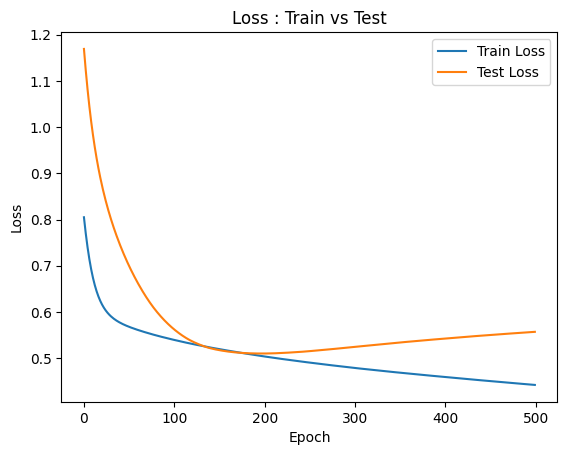

In [238]:
def accuracy(model, x, y):
    acc = ((model(x).view(-1) >= 0.5).float() == y).float().mean()
    return acc.item()

model = MultilayerPerceptron(2, 10)
criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

train_loss = []
test_loss = []
test_accuracy = []

for epoch in range(500) :
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred.view(-1), y_train) # pb de dim donc view nécessaire
    loss.backward()
    optimizer.step()

    model.eval()
    y_pred = model(x_test)
    after_train = criterion(y_pred.squeeze(), y_test)
    print('Test loss after Training' , after_train.item())

    train_loss.append(loss.item())
    test_loss.append(after_train.item())

    acc_test = accuracy(model, x_test, y_test)
    test_accuracy.append(acc_test)

plt.figure()
plt.plot(train_loss, label="Train Loss")
plt.plot(test_loss, label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss : Train vs Test")
plt.legend()
plt.show()

- Pendant les premières époques, le modèle est en sous-apprentissage : les deux pertes baissent
- Au-delà de 200 époques, la perte d’entraînement continue de baisser alors que la perte de test remonte : c’est le début de sur-apprentissage

16. Non linearly separable data. Generate a dataset with `make_moons(n_samples=300, noise=0.2, random_state=0)` (train/test split 70/30).

    a. Train a single-layer model (`nn.Linear(2, 1)` followed by a Sigmoid, BCE loss) and your MLP.

    b. For each model, plot the decision regions (hint: evaluate the model on a grid built with `np.meshgrid`, then use `plt.contourf`) and give the test accuracy.

    c. Conclude: what does the hidden layer bring?

Accuracy MLP : 0.8777777552604675
Accuracy linéaire : 0.8444444537162781


Text(0.5, 1.0, 'Modèle MLP')

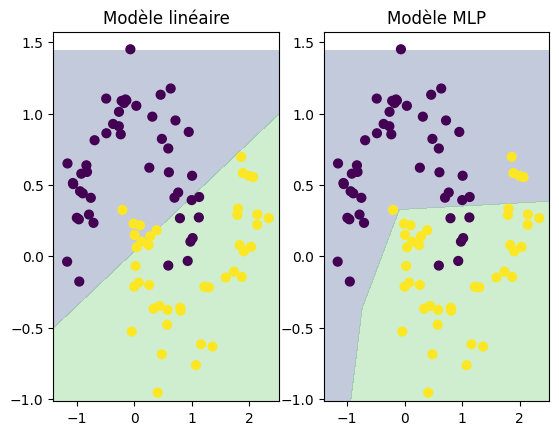

In [239]:
x,y = make_moons(n_samples=300, noise=0.2, random_state=0)
X = torch.tensor(x, dtype=torch.float32)
Y = torch.tensor(y, dtype=torch.float32)

torch.manual_seed(123)
shuffle_idx = torch.randperm(Y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = Y[shuffle_idx[:percent70]], Y[shuffle_idx[percent70:]]

linear = nn.Sequential(nn.Linear(2, 1), nn.Sigmoid())
criterion = nn.BCELoss()

model = MultilayerPerceptron(2, 10)

optimizer_linear = torch.optim.SGD(linear.parameters(), lr=0.1)
optimizer_model = torch.optim.SGD(model.parameters(), lr=0.2)

for epoch in range(500):
        linear.train()
        optimizer_linear.zero_grad()
        y_pred = linear(X_train).view(-1)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer_linear.step()


for epoch in range(1500):
        model.train()
        optimizer_model.zero_grad()
        y_pred = model(X_train).view(-1)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer_model.step()

acc_model = accuracy(model, X_test, y_test)
acc_linear = accuracy(linear, X_test, y_test)

print("Accuracy MLP :", acc_model)
print("Accuracy linéaire :", acc_linear)

x_meshgrid, y_meshgrid = np.meshgrid( # génère suite régulière de nombres
    np.arange(X[:, 0].min(), X[:, 0].max(), 0.02),
    np.arange(X[:, 1].min(), X[:, 1].max(), 0.02)
)

grid = torch.tensor(np.c_[x_meshgrid.ravel(), y_meshgrid.ravel()], dtype=torch.float32)

with torch.no_grad():
    Z_linear = linear(grid).reshape(x_meshgrid.shape).numpy()
    Z_model = model(grid).reshape(x_meshgrid.shape).numpy()

fig, ax = plt.subplots(1, 2)
ax[0].contourf(x_meshgrid, y_meshgrid, Z_linear, levels=[0, 0.5, 1], alpha=0.3)
ax[0].scatter(X_test[:, 0],X_test[:, 1],c=y_test,s=40)
ax[0].set_title(f"Modèle linéaire")

ax[1].contourf(x_meshgrid, y_meshgrid, Z_model, levels=[0, 0.5, 1], alpha=0.3)
ax[1].scatter(X_test[:, 0],X_test[:, 1],c=y_test,s=40)
ax[1].set_title(f"Modèle MLP")

# on a augmenté le nombre d'epoch et le learning rate pour avoir une frontière + courbée

17. In order to improve the model, you can try out different values for your
hyperparameters (hidden dimension size, number of epochs, learning rate). You can also
try changing the structure of your model (adding more hidden layers). Summarize your experiments in a table (configuration, test accuracy) and justify your best choice.

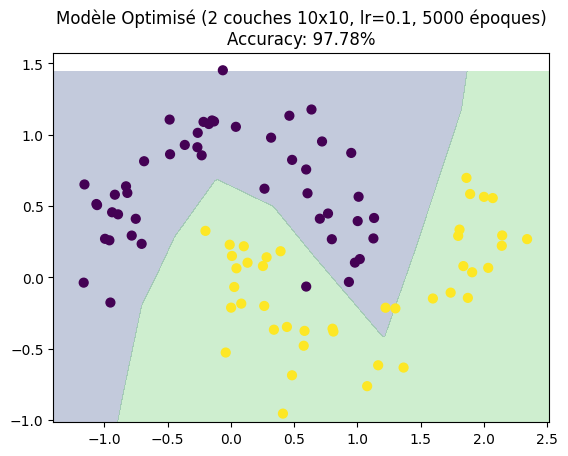

In [240]:
class MultilayerPerceptron_Optimised(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1, num_hidden_2):
        super(MultilayerPerceptron_Optimised, self).__init__()
        self.hidden_layer_1 = torch.nn.Linear(num_features, num_hidden_1)
        self.hidden_layer_2 = torch.nn.Linear(num_hidden_1, num_hidden_2)
        self.output_layer = torch.nn.Linear(num_hidden_2, 1)

    def forward(self, x):
        x = torch.relu(self.hidden_layer_1(x))
        x = torch.relu(self.hidden_layer_2(x))
        out = torch.sigmoid(self.output_layer(x))
        return out

model_opti = MultilayerPerceptron_Optimised(2, 10, 10)
criterion = nn.BCELoss()
optimizer_opti = torch.optim.SGD(model_opti.parameters(), lr=0.1)

for epoch in range(5000):
    model_opti.train()
    optimizer_opti.zero_grad()
    y_pred = model_opti(X_train).view(-1)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer_opti.step()

model_opti.eval()
with torch.no_grad():
    acc_opti = accuracy(model_opti, X_test, y_test)
    Z_opti = model_opti(grid).reshape(x_meshgrid.shape).numpy()


plt.figure()
plt.contourf(x_meshgrid, y_meshgrid, Z_opti, levels=[0, 0.5, 1], alpha=0.3)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=40)
plt.title(
    f"Modèle Optimisé (2 couches 10x10, lr=0.1, 5000 époques)\nAccuracy: {acc_opti * 100:.2f}%"
)
plt.show()

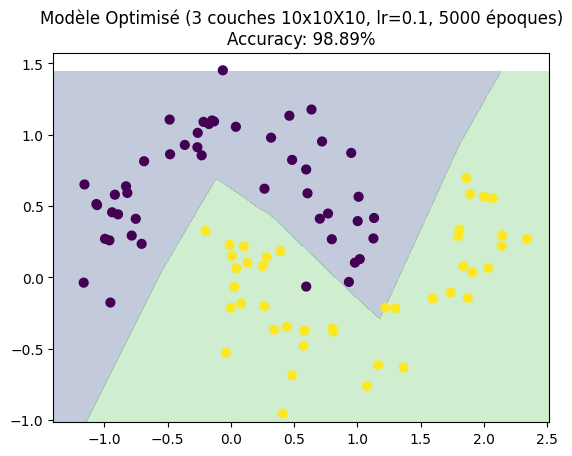

In [241]:
class MultilayerPerceptron_Optimised_1(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1, num_hidden_2,num_hidden_3):
        super(MultilayerPerceptron_Optimised_1, self).__init__()
        self.hidden_layer_1 = torch.nn.Linear(num_features, num_hidden_1)
        self.hidden_layer_2 = torch.nn.Linear(num_hidden_1, num_hidden_2)
        self.hidden_layer_3 = torch.nn.Linear(num_hidden_2,num_hidden_3)
        self.output_layer = torch.nn.Linear(num_hidden_3, 1)

    def forward(self, x):
        x = torch.relu(self.hidden_layer_1(x))
        x = torch.relu(self.hidden_layer_2(x))
        x = torch.relu(self.hidden_layer_3(x))
        out = torch.sigmoid(self.output_layer(x))
        return out


model_opti_1 = MultilayerPerceptron_Optimised_1(2, 10, 10, 10)
criterion = nn.BCELoss()
optimizer_opti = torch.optim.SGD(model_opti_1.parameters(), lr=0.1)


for epoch in range(5000):
    model_opti_1.train()
    optimizer_opti.zero_grad()
    y_pred = model_opti_1(X_train).view(-1)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer_opti.step()

model_opti_1.eval()
with torch.no_grad():
    acc_opti = accuracy(model_opti_1, X_test, y_test)
    Z_opti = model_opti_1(grid).reshape(x_meshgrid.shape).numpy()


plt.figure()
plt.contourf(x_meshgrid, y_meshgrid, Z_opti, levels=[0, 0.5, 1], alpha=0.3)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, s=40)
plt.title(
    f"Modèle Optimisé (3 couches 10x10X10, lr=0.1, 5000 époques)\nAccuracy: {acc_opti * 100:.2f}%"
)
plt.show()

In [242]:
# Fait par claude car on voulait avoir des tests corrects :

def make_mlp(sizes):
    layers = []
    for a, b in zip(sizes[:-1], sizes[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    layers[-1] = nn.Sigmoid()          # dernière activation = sigmoïde
    return nn.Sequential(*layers)

configs = [([2, 5, 1], 0.2, 1500), ([2, 10, 1], 0.2, 1500), ([2, 50, 1], 0.2, 1500),
           ([2, 10, 10, 1], 0.2, 1500), ([2, 10, 10, 10, 1], 0.2, 1500),
           ([2, 10, 10, 1], 0.1, 5000)]
rows = []
for sizes, lr, n_ep in configs:
    torch.manual_seed(0)
    m = make_mlp(sizes)
    opt = torch.optim.SGD(m.parameters(), lr=lr)
    for _ in range(n_ep):
        opt.zero_grad()
        criterion(m(X_train).view(-1), y_train).backward()
        opt.step()
    rows.append({"config": sizes[1:-1], "lr": lr, "epochs": n_ep,
                 "test_acc": accuracy(m, X_test, y_test)})
pd.DataFrame(rows)

,config,lr,epochs,test_acc
0,[5],0.2,1500,0.877778
1,[10],0.2,1500,0.988889
2,[50],0.2,1500,0.988889
3,"[10, 10]",0.2,1500,0.977778
4,"[10, 10, 10]",0.2,1500,0.966667
5,"[10, 10]",0.1,5000,0.977778


- Le modèle linéaire n'est pas le meilleur car sa frontière est forcément une droite, alors que les deux lunes s’imbriquent l'une dans l'autre.
- Dès qu’on ajoute une couche cachée ReLU, la frontière devient linéaire par morceaux et prend plus la forme des classes (l'acc monte).
- Passer à 2 ou 3 couches, élargir la couche ou augmenter le nombre d’époques ne change presque rien : on atteint un plateau car avec noise=0.2 les classes se chevauchent et aucune frontière ne peut atteindre 100 %


Donc le modèle le plus simple situé sur ce plateau est celui avec 1 couche cachée de 10 neurones, lr = 0,2, 1500 époques car il généralise aussi bien pour un coût moindre. Les très gros modèles ou les très longs entraînements risquent de faire du sur-apprentissage (ce qui se voit à une frontière trop tordue)